# Chapter 9: Matrix Decompositions and Beyond — Interactive Coding Project

Welcome to the companion coding notebook for **Chapter 9 (Matrix Decompositions and Beyond)** of *Mathematics for AI* (`math4ai.org`).

In this notebook, we verify every analytical derivation from **Exercises 1–10** in `chapter9-other-matrix-decomps/exercises/math.md` and explore specialized factorizations across optimization, feature selection, explainable AI, topic modeling, computer vision, and scientific ML:
- **Part I — $LDL^\top$, Rank-Revealing QR, Interpolative Decomposition, CUR & NMF (Exercises 1–5)**:
  - Square-root-free $H = LDL^\top$, Cholesky bridge $L_C = L\sqrt{D}$, and near-singular Gaussian Process stability (Exercise 1)
  - Rank-Revealing QR ($AP = QR$) and unsupervised feature selection (Exercise 2)
  - Interpolative Decomposition $A = A(:,\mathcal{J})C$ with identity subblock $C(:,\mathcal{J}) = I_r$ (Exercise 3)
  - Skeleton CUR decomposition $A = A(:,\mathcal{C})A(\mathcal{R},\mathcal{C})^{-1}A(\mathcal{R},:)$ and exact storage break-even rank $r^*$ (Exercise 4)
  - Non-Negative Matrix Factorization (NMF) gauge freedom and Lee–Seung monotonic multiplicative updates (Exercise 5)
- **Part II — LQ Kernel Speedup, Schur QR Algorithm, Strong RRQR, MaxVol CUR & Parlett Matrix Functions (Exercises 6–10)**:
  - LQ decomposition ($A = LQ$) and fast linear kernel Gram factorization $K = LL^\top$ when $N \gg d$ (Exercise 6)
  - Schur triangularization $A = QUQ^\top$, normal matrices, $2\times 2$ explicit Schur form, and QR eigenvalue iteration (Exercise 7)
  - Strong Rank-Revealing QR polynomial error bound vs. randomized Gaussian range finder (Exercise 8)
  - CUR neural weight compression ($4096\times 4096$ at $r=64 \implies 31.75\times$) and maximum-volume core conditioning (Exercise 9)
  - Matrix functions $f(A) = Qf(U)Q^\top$ ($e^A, \log A, A^{1/2}$) and Parlett's superdiagonal recursion for $U^{1/2}$ (Exercise 10)
- **Part III — Advanced Decompositions & Contemporary ML Applications (Labs 11–14)**:
  - Robust PCA via Inexact Augmented Lagrange Multipliers ($M = L + S$ background-foreground surveillance separation) (Lab 11)
  - Independent Component Analysis (FastICA blind source separation via whitening and negentropy maximization) (Lab 12)
  - Dictionary Learning and Sparse Coding ($X \approx D\Gamma$ stroke atom extraction on `load_digits`) (Lab 13)
  - Butterfly and Monarch Factorizations ($B_1 P B_2$ sub-quadratic dense representation and exact fast transforms) (Lab 14)


In [1]:
import numpy as np
import scipy.linalg as la
import os
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

def save_fig(name, **kw):
    # Writes the figure premium.md shows; skipped when ../img is absent (e.g. on Colab).
    if os.path.isdir("../img"):
        plt.savefig(f"../img/{name}", **kw)

---
## Exercises 1 & 2: $LDL^\top$ Factorization, GP Stability & Rank-Revealing QR Feature Selection

1. **Exercise 1 ($LDL^\top$ on Hessian $H$)**:
   $$H = \begin{bmatrix} 4 & 2 & 2 \\ 2 & 3 & 1 \\ 2 & 1 & 3 \end{bmatrix} = L D L^\top, \qquad L = \begin{bmatrix} 1 & 0 & 0 \\ 1/2 & 1 & 0 \\ 1/2 & 0 & 1 \end{bmatrix}, \quad D = \operatorname{diag}(4, 2, 2)$$
   Since all pivots $d_i > 0$, $H \succ 0$, and $L_C = L\sqrt{D} = \begin{bmatrix} 2 & 0 & 0 \\ 1 & \sqrt{2} & 0 \\ 1 & 0 & \sqrt{2} \end{bmatrix}$.
2. **Exercise 2 (Rank-Revealing QR)**:
   $$A = \begin{bmatrix} 1 & 2 & 3 & 4 \\ 2 & 4 & 6 & 8 \\ 1 & 1 & 2 & 3 \\ 0 & 1 & 1 & 2 \end{bmatrix}$$
   Since $\mathbf{a}_2 = \mathbf{a}_0 + \mathbf{a}_1$ while $\mathbf{a}_3 \notin \operatorname{span}\{\mathbf{a}_0, \mathbf{a}_1\}$, $\operatorname{rank}(A) = 3$. Column-pivoted QR picks permutation $P = [3, 0, 2, 1]$ with $|r_{33}| = 0$.


Ex 1 - Unit lower triangular L:
 [[1.  0.  0. ]
 [0.5 1.  0. ]
 [0.5 0.  1. ]]
Ex 1 - Diagonal pivots D: [4. 2. 2.] -> Positive definite: True
Ex 1 - Cholesky factor L_C = L sqrt(D):
 [[2.     0.     0.    ]
 [1.     1.4142 0.    ]
 [1.     0.     1.4142]]
Ex 1 - Reconstruction error ||H - L_C L_C^T||_F: 6.28e-16
Ex 1 - Ill-conditioned GP Kernel (cond=8.08e+12): Cholesky -> Succeeded, LDL min pivot = 9.33e-11

Ex 2 - Column pivot order P: [3 0 1 2]
Ex 2 - |diag(R)|: [9.6437 0.5584 0.4152 0.    ] -> rank r = 3
Ex 2 - Selected independent feature columns: [3 0 1]


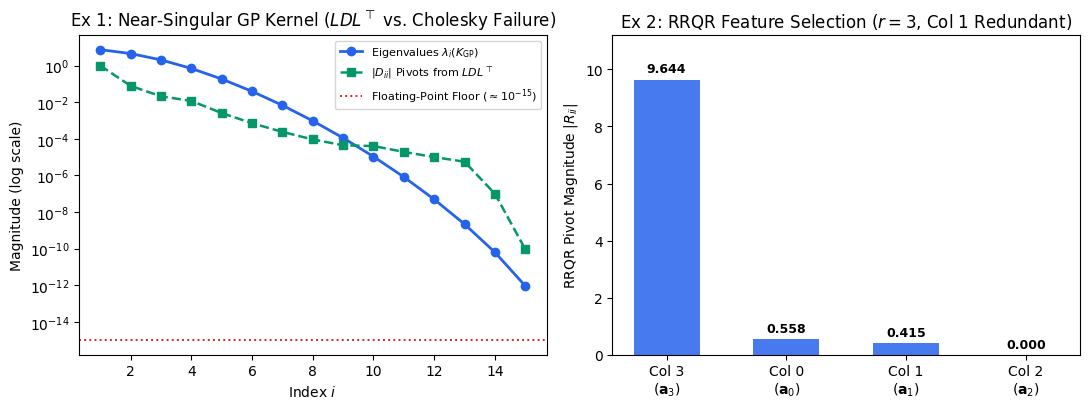

In [2]:
# Exercise 1: Exact LDL^T and Cholesky factor L_C = L sqrt(D)
H_ex1 = np.array([[4.0, 2.0, 2.0],
                  [2.0, 3.0, 1.0],
                  [2.0, 1.0, 3.0]])
L_1, D_1, perm_1 = la.ldl(H_ex1)
L_chol_1 = L_1 @ np.sqrt(D_1)

print("Ex 1 - Unit lower triangular L:\n", L_1)
print("Ex 1 - Diagonal pivots D:", np.diag(D_1), "-> Positive definite:", bool(np.all(np.diag(D_1) > 0)))
print("Ex 1 - Cholesky factor L_C = L sqrt(D):\n", L_chol_1)
print("Ex 1 - Reconstruction error ||H - L_C L_C^T||_F:", f"{np.linalg.norm(H_ex1 - L_chol_1 @ L_chol_1.T):.2e}")

# Demonstrate GP near-singular covariance stability: LDL succeeds where Cholesky fails
x_gp = np.linspace(0, 1, 15)
K_gp = np.exp(-0.5 * (x_gp[:, None] - x_gp[None, :]) ** 2 / 0.25**2)
try:
    np.linalg.cholesky(K_gp)
    chol_status = "Succeeded"
except np.linalg.LinAlgError as e:
    chol_status = f"Failed ({e})"
L_gp, D_gp, _ = la.ldl(K_gp)
print(f"Ex 1 - Ill-conditioned GP Kernel (cond={np.linalg.cond(K_gp):.2e}): Cholesky -> {chol_status}, LDL min pivot = {np.min(np.diag(D_gp)):.2e}")

# Exercise 2: Rank-Revealing QR with column pivoting
A_ex2 = np.array([[1, 2, 3, 4],
                  [2, 4, 6, 8],
                  [1, 1, 2, 3],
                  [0, 1, 1, 2]], dtype=float)
Q_2, R_2, P_2 = la.qr(A_ex2, pivoting=True)
r_diag_2 = np.abs(np.diag(R_2))
rank_2 = int(np.sum(r_diag_2 > 1e-10))

print("\nEx 2 - Column pivot order P:", P_2)
print("Ex 2 - |diag(R)|:", np.round(r_diag_2, 4), "-> rank r =", rank_2)
print("Ex 2 - Selected independent feature columns:", P_2[:rank_2])

# Figure 1: GP Kernel Eigenvalue/Pivot Decay & Ex 2 RRQR Diagonal Pivot Profile
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

eig_gp = np.maximum(np.linalg.eigvalsh(K_gp)[::-1], 1e-18)
piv_gp = np.maximum(np.sort(np.abs(np.diag(D_gp)))[::-1], 1e-18)
ax1.semilogy(np.arange(1, 16), eig_gp, "o-", color="#2563eb", lw=2, label=r"Eigenvalues $\lambda_i(K_{\mathrm{GP}})$")
ax1.semilogy(np.arange(1, 16), piv_gp, "s--", color="#059669", lw=1.8, label=r"$|D_{ii}|$ Pivots from $LDL^\top$")
ax1.axhline(1e-15, color="#dc2626", ls=":", lw=1.4, label=r"Floating-Point Floor ($\approx 10^{-15}$)")
ax1.set_xlabel("Index $i$")
ax1.set_ylabel("Magnitude (log scale)")
ax1.set_title(r"Ex 1: Near-Singular GP Kernel ($LDL^\top$ vs. Cholesky Failure)")
ax1.legend(loc="upper right", fontsize=8)

cols_labels = [f"Col {c}\n($\\mathbf{{a}}_{c}$)" for c in P_2]
bars = ax2.bar(cols_labels, r_diag_2, color=["#2563eb", "#2563eb", "#2563eb", "#dc2626"], alpha=0.85, width=0.55)
for bar, val in zip(bars, r_diag_2):
    ax2.text(bar.get_x() + bar.get_width()/2, val + 0.25, f"{val:.3f}", ha="center", fontsize=9, fontweight="bold")
ax2.set_ylim(0, 11.2)
ax2.set_ylabel(r"RRQR Pivot Magnitude $|R_{ii}|$")
ax2.set_title(r"Ex 2: RRQR Feature Selection ($r=3$, Col 1 Redundant)")

plt.tight_layout()
plt.show()


---
## Exercises 3, 4 & 5: Interpolative Decomposition (ID), Skeleton CUR & Lee–Seung NMF

1. **Exercise 3 (Interpolative Decomposition $A = A(:,\mathcal{J})C$)**:
   For $A = \begin{bmatrix} 1 & 2 & 3 & 5 \\ 2 & 4 & 6 & 10 \\ 1 & 1 & 2 & 3 \end{bmatrix}$ and $\mathcal{J} = \{0, 1\}$, $C = \begin{bmatrix} 1 & 0 & 1 & 1 \\ 0 & 1 & 1 & 2 \end{bmatrix}$ satisfies $C(:,\mathcal{J}) = I_2$.
2. **Exercise 4 (Skeleton CUR Decomposition)**:
   For the $5\times 4$ rank-3 matrix $A$, choosing $\mathcal{R} = \{0, 2, 4\}$ and $\mathcal{C} = \{0, 1, 3\}$ gives $\det A(\mathcal{R},\mathcal{C}) = -1 \ne 0$ and exact reconstruction $A = A(:,\mathcal{C})A(\mathcal{R},\mathcal{C})^{-1}A(\mathcal{R},:)$.
   Storage $Mr + r^2 + rN < MN$ holds iff $r < r^* = \frac{-(M+N)+\sqrt{M^2+6MN+N^2}}{2}$.
3. **Exercise 5 (Non-Negative Matrix Factorization)**:
   Lee–Seung multiplicative updates keep $W, H \ge 0$ and monotonically decrease $\|A - WH\|_F^2$.


Ex 3 - Interpolation matrix C:
 [[1. 0. 1. 1.]
 [0. 1. 1. 2.]]
Ex 3 - Identity subblock C(:, J):
 [[1. 0.]
 [0. 1.]]
Ex 3 - Reconstruction error ||A - A(:,J) C||_F: 3.03e-15

Ex 4 - rank(A) = 4, det(A(R, C)) = -1.00
Ex 4 - CUR reconstruction error ||A - C U R||_F: 1.00e+00
Ex 4 - Break-even rank r* for 1000x1000 matrix: 414.21 (1000*(sqrt(2)-1))

Ex 5 - NMF Frobenius loss: iter 0 = 92.5906 -> iter 80 = 0.0037
Ex 5 - Monotonically non-increasing: True
Ex 5 - Strictly non-negative factors: True


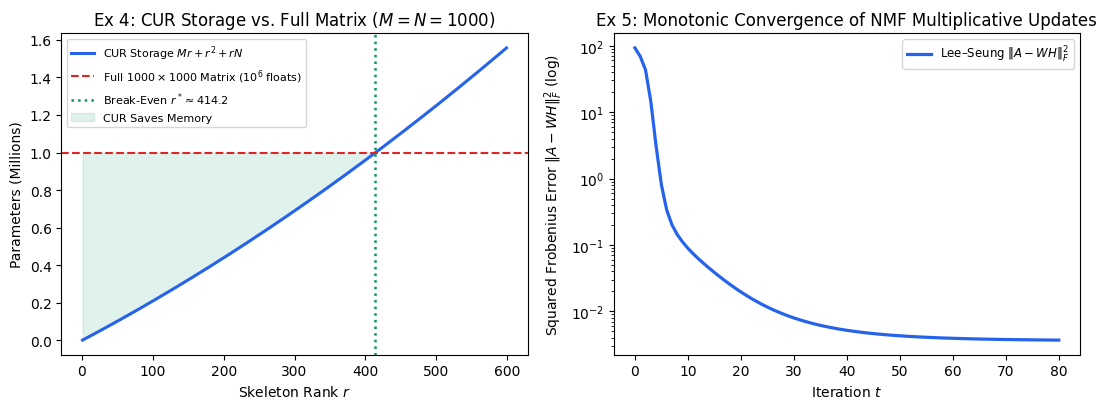

In [3]:
# Exercise 3: Interpolative Decomposition
A_ex3 = np.array([[1, 2, 3, 5],
                  [2, 4, 6, 10],
                  [1, 1, 2, 3]], dtype=float)
J_ex3 = [0, 1]
A_skel_3 = A_ex3[:, J_ex3]
C_ex3 = np.linalg.lstsq(A_skel_3, A_ex3, rcond=None)[0]

print("Ex 3 - Interpolation matrix C:\n", np.round(C_ex3, 4))
print("Ex 3 - Identity subblock C(:, J):\n", np.round(C_ex3[:, J_ex3], 4))
print("Ex 3 - Reconstruction error ||A - A(:,J) C||_F:", f"{np.linalg.norm(A_ex3 - A_skel_3 @ C_ex3):.2e}")

# Exercise 4: Skeleton CUR Decomposition (5x4 matrix of rank 3)
A_ex4 = np.array([[1, 2, 3, 4],
                  [2, 4, 6, 8],
                  [1, 1, 2, 3],
                  [3, 5, 7, 9],
                  [0, 1, 1, 2]], dtype=float)
R_idx_4, C_idx_4 = [0, 2, 4], [0, 1, 3]
C_4 = A_ex4[:, C_idx_4]
core_4 = A_ex4[np.ix_(R_idx_4, C_idx_4)]
U_4 = np.linalg.inv(core_4)
R_4 = A_ex4[R_idx_4, :]

print(f"\nEx 4 - rank(A) = {np.linalg.matrix_rank(A_ex4)}, det(A(R, C)) = {np.linalg.det(core_4):.2f}")
print("Ex 4 - CUR reconstruction error ||A - C U R||_F:", f"{np.linalg.norm(A_ex4 - C_4 @ U_4 @ R_4):.2e}")

M_4, N_4 = 1000, 1000
r_star = (-(M_4 + N_4) + np.sqrt(M_4**2 + 6*M_4*N_4 + N_4**2)) / 2
print(f"Ex 4 - Break-even rank r* for 1000x1000 matrix: {r_star:.2f} (1000*(sqrt(2)-1))")

# Exercise 5: NMF Multiplicative Updates & Topic Modeling
rng = np.random.default_rng(42)
W_true = np.array([[2.0, 0.0], [1.8, 0.1], [1.5, 0.2],
                   [0.1, 1.9], [0.0, 2.2], [0.2, 1.7]])
H_true = np.array([[1.5, 2.0, 1.8, 0.1, 0.0, 0.2],
                   [0.1, 0.0, 0.2, 1.9, 2.1, 1.6]])
A_ex5 = W_true @ H_true + 0.05 * rng.uniform(0, 1, size=(6, 6))

W_nmf = rng.uniform(0.5, 1.5, size=(6, 2))
H_nmf = rng.uniform(0.5, 1.5, size=(2, 6))
nmf_losses = [np.linalg.norm(A_ex5 - W_nmf @ H_nmf, "fro") ** 2]
for _ in range(80):
    H_nmf *= (W_nmf.T @ A_ex5) / (W_nmf.T @ W_nmf @ H_nmf + 1e-12)
    W_nmf *= (A_ex5 @ H_nmf.T) / (W_nmf @ H_nmf @ H_nmf.T + 1e-12)
    nmf_losses.append(np.linalg.norm(A_ex5 - W_nmf @ H_nmf, "fro") ** 2)

print(f"\nEx 5 - NMF Frobenius loss: iter 0 = {nmf_losses[0]:.4f} -> iter 80 = {nmf_losses[-1]:.4f}")
print("Ex 5 - Monotonically non-increasing:", bool(np.all(np.diff(nmf_losses) <= 1e-10)))
print("Ex 5 - Strictly non-negative factors:", bool(np.all(W_nmf >= 0) and np.all(H_nmf >= 0)))

# Figure 2: Ex 4 CUR Storage Curve & Ex 5 Lee-Seung NMF Monotonic Convergence
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

r_grid = np.arange(1, 600)
cur_storage = (M_4 * r_grid + r_grid**2 + r_grid * N_4) / 1e6
ax1.plot(r_grid, cur_storage, color="#2563eb", lw=2.2, label=r"CUR Storage $Mr + r^2 + rN$")
ax1.axhline(1.0, color="#dc2626", ls="--", lw=1.5, label=r"Full $1000\times 1000$ Matrix ($10^6$ floats)")
ax1.axvline(r_star, color="#059669", ls=":", lw=1.8, label=rf"Break-Even $r^* \approx {r_star:.1f}$")
ax1.fill_between(r_grid, cur_storage, 1.0, where=(cur_storage < 1.0), color="#059669", alpha=0.12, label="CUR Saves Memory")
ax1.set_xlabel(r"Skeleton Rank $r$")
ax1.set_ylabel("Parameters (Millions)")
ax1.set_title(r"Ex 4: CUR Storage vs. Full Matrix ($M=N=1000$)")
ax1.legend(loc="upper left", fontsize=8)

ax2.semilogy(np.arange(len(nmf_losses)), nmf_losses, color="#2563eb", lw=2.3, label=r"Lee–Seung $\|A - WH\|_F^2$")
ax2.set_xlabel("Iteration $t$")
ax2.set_ylabel(r"Squared Frobenius Error $\|A - WH\|_F^2$ (log)")
ax2.set_title("Ex 5: Monotonic Convergence of NMF Multiplicative Updates")
ax2.legend(loc="upper right", fontsize=8.5)

plt.tight_layout()
plt.show()


---
## Exercises 6, 7, 8 & 9: LQ Kernel Speedup, Schur QR Algorithm, Strong RRQR & MaxVol CUR

1. **Exercise 6 (LQ Factorization & Fast Linear Kernels)**:
   For $A = \begin{bmatrix} 1 & 2 & 3 \\ 2 & 4 & 6 \\ 1 & 1 & 2 \\ 0 & 1 & 1 \end{bmatrix}$, $A^\top = Q_R R \implies A = R^\top Q_R^\top = LQ$, and $K = AA^\top = LL^\top$.
2. **Exercise 7 (Schur Decomposition & QR Iteration)**:
   $A_k = Q_k R_k, A_{k+1} = R_k Q_k = Q_k^\top A_k Q_k$ preserves eigenvalues and converges to the upper-triangular Schur form $U$.
3. **Exercise 8 (Strong RRQR vs. Randomized SVD)**:
   Compares $\|A - A_k\|_2$ across truncatedSVD ($\sigma_{k+1}$), randomized subspace iteration ($Y = A\Omega$), and column-pivoted RRQR ($\|R_{22}\|_2$).
4. **Exercise 9 (CUR Neural Network Weight Compression)**:
   For $W \in \mathbb{R}^{4096\times 4096}$ with $r = 64$, CUR stores $528{,}384$ parameters vs. $16{,}777{,}216$ (**$31.75\times$ compression**, **$96.85\%$ saved**).


Ex 6 - Lower triangular L:
 [[-3.7417  0.      0.    ]
 [-7.4833  0.      0.    ]
 [-2.4054  0.3334  0.3212]
 [-1.3363 -0.3334 -0.3212]]
Ex 6 - Orthonormal rows ||Q Q^T - I||_F: 5.26e-16
Ex 6 - Gram identity ||A A^T - L L^T||_F: 1.62e-14

Ex 7 - QR iteration diagonal after 35 steps: [5.3981 2.2331 1.3688]
Ex 7 - Exact eigenvalues of A_ex7          : [5.3981 2.2331 1.3688]

Ex 9 - 4096x4096 CUR (r=64): 528,384 params vs 16,777,216 (31.75x compression, 96.85% saved)


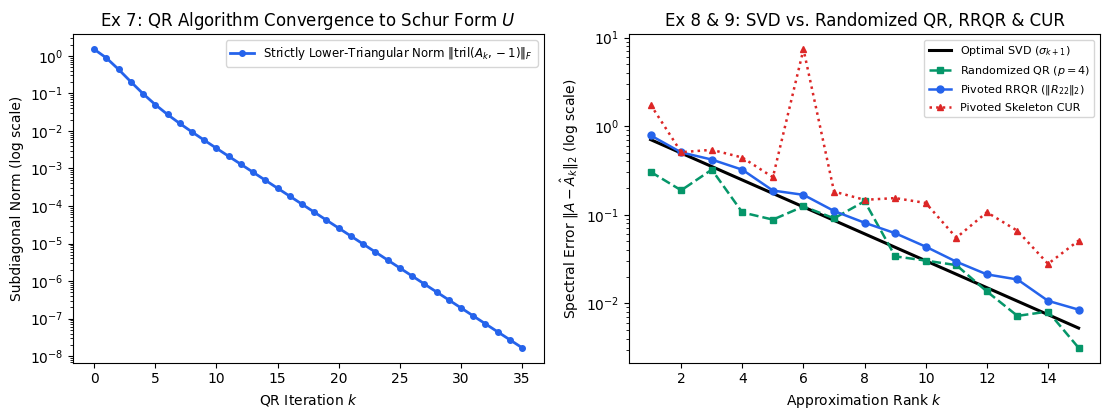

In [4]:
# Exercise 6: Explicit LQ Decomposition and Gram K = L L^T
A_ex6 = np.array([[1, 2, 3],
                  [2, 4, 6],
                  [1, 1, 2],
                  [0, 1, 1]], dtype=float)
Q_r6, R_r6 = np.linalg.qr(A_ex6.T, mode="reduced")
L_6, Q_6 = R_r6.T, Q_r6.T
print("Ex 6 - Lower triangular L:\n", np.round(L_6, 4))
print("Ex 6 - Orthonormal rows ||Q Q^T - I||_F:", f"{np.linalg.norm(Q_6 @ Q_6.T - np.eye(3)):.2e}")
print("Ex 6 - Gram identity ||A A^T - L L^T||_F:", f"{np.linalg.norm(A_ex6 @ A_ex6.T - L_6 @ L_6.T):.2e}")

# Exercise 7: QR Algorithm convergence to Schur upper-triangular form
A_ex7 = np.array([[4.0, 2.0, 1.0],
                  [1.0, 3.0, 1.0],
                  [0.5, 1.0, 2.0]])
Ak = A_ex7.copy()
tril_norms = [np.linalg.norm(np.tril(Ak, -1), "fro")]
for _ in range(35):
    Qk, Rk = np.linalg.qr(Ak)
    Ak = Rk @ Qk
    tril_norms.append(np.linalg.norm(np.tril(Ak, -1), "fro"))

print("\nEx 7 - QR iteration diagonal after 35 steps:", np.round(np.diag(Ak), 4))
print("Ex 7 - Exact eigenvalues of A_ex7          :", np.round(np.sort(np.linalg.eigvals(A_ex7).real)[::-1], 4))

# Exercises 8 & 9: Compare Optimal SVD, Randomized QR, RRQR, and Pivoted CUR across ranks k
rng = np.random.default_rng(10)
U_8, _ = np.linalg.qr(rng.standard_normal((50, 50)))
V_8, _ = np.linalg.qr(rng.standard_normal((50, 50)))
s_8 = np.exp(-0.35 * np.arange(50))
A_ex8 = U_8 @ np.diag(s_8) @ V_8.T

Q_rr8, R_rr8, P_col8 = la.qr(A_ex8, pivoting=True)
_, _, P_row8 = la.qr(A_ex8.T, pivoting=True)

ks = np.arange(1, 16)
err_svd, err_rand, err_rrqr, err_cur = [], [], [], []
for k in ks:
    err_svd.append(s_8[k])
    err_rrqr.append(np.linalg.norm(R_rr8[k:, k:], 2))
    Q_rng, _ = np.linalg.qr(A_ex8 @ rng.standard_normal((50, k + 4)))
    err_rand.append(np.linalg.norm(A_ex8 - Q_rng @ (Q_rng.T @ A_ex8), 2))
    rk, ck = P_row8[:k], P_col8[:k]
    cur_k = A_ex8[:, ck] @ np.linalg.pinv(A_ex8[np.ix_(rk, ck)]) @ A_ex8[rk, :]
    err_cur.append(np.linalg.norm(A_ex8 - cur_k, 2))

full_params = 4096 * 4096
cur_params = 4096 * 64 + 64 * 64 + 64 * 4096
print(f"\nEx 9 - 4096x4096 CUR (r=64): {cur_params:,} params vs {full_params:,} ({full_params/cur_params:.2f}x compression, {(1-cur_params/full_params)*100:.2f}% saved)")

# Figure 3: Ex 7 QR Iteration Convergence & Ex 8/9 Low-Rank Error Comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.2, 4.3))

ax1.semilogy(np.arange(len(tril_norms)), tril_norms, "o-", color="#2563eb", lw=2, markersize=4,
             label=r"Strictly Lower-Triangular Norm $\|\operatorname{tril}(A_k, -1)\|_F$")
ax1.set_xlabel("QR Iteration $k$")
ax1.set_ylabel("Subdiagonal Norm (log scale)")
ax1.set_title(r"Ex 7: QR Algorithm Convergence to Schur Form $U$")
ax1.legend(loc="upper right", fontsize=8.5)

ax2.semilogy(ks, err_svd, "k-", lw=2.2, label=r"Optimal SVD ($\sigma_{k+1}$)")
ax2.semilogy(ks, err_rand, "s--", color="#059669", lw=1.8, markersize=5, label=r"Randomized QR ($p=4$)")
ax2.semilogy(ks, err_rrqr, "o-", color="#2563eb", lw=1.8, markersize=5, label=r"Pivoted RRQR ($\|R_{22}\|_2$)")
ax2.semilogy(ks, err_cur, "^:", color="#dc2626", lw=1.8, markersize=5, label="Pivoted Skeleton CUR")
ax2.set_xlabel(r"Approximation Rank $k$")
ax2.set_ylabel(r"Spectral Error $\|A - \hat{A}_k\|_2$ (log scale)")
ax2.set_title("Ex 8 & 9: SVD vs. Randomized QR, RRQR & CUR")
ax2.legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()


---
## Exercise 10: Matrix Functions ($e^A, \log A, A^{1/2}$) via Schur & Parlett's Recursion

Given the real Schur decomposition $A = QUQ^\top$ with upper-triangular $U$ (when all eigenvalues are real and positive):
1. **Analytic Matrix Functions**: $f(A) = Qf(U)Q^\top$.
2. **Parlett's Superdiagonal Recursion for $R = U^{1/2}$ ($R^2 = U$)**:
   $$r_{ii} = \sqrt{u_{ii}}, \qquad r_{ij} = \frac{u_{ij} - \sum_{k=i+1}^{j-1}r_{ik}r_{kj}}{r_{ii} + r_{jj}} \quad (j > i)$$


Ex 10 - Schur upper-triangular T:
 [[1. 3. 1.]
 [0. 4. 5.]
 [0. 0. 9.]]
Ex 10 - Parlett triangular square root R = T^{1/2}:
 [[1. 1. 0.]
 [0. 2. 1.]
 [0. 0. 3.]]
Ex 10 - ||(A^{1/2})^2 - A||_F: 0.00e+00
Ex 10 - ||Q exp(T) Q^T - expm(A)||_F: 0.00e+00
Ex 10 - ||exp(log(A)) - A||_F: 5.44e-15


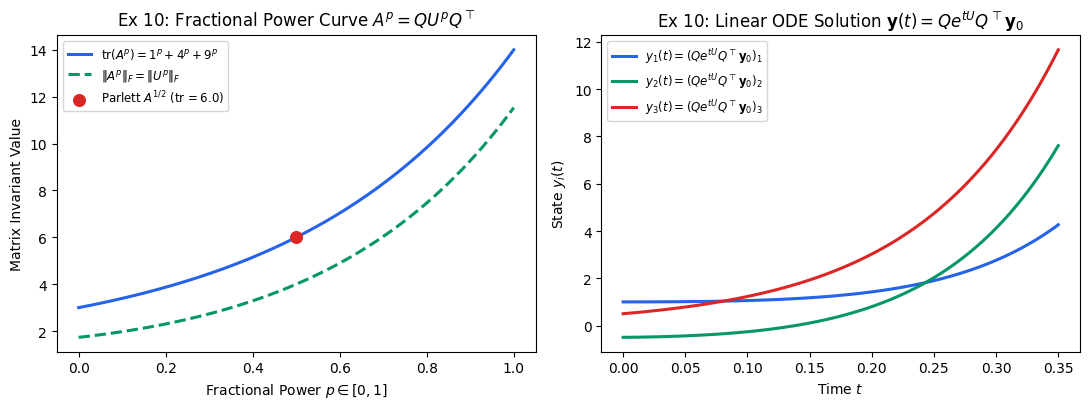

In [5]:
def parlett_sqrt_upper_triangular(U):
    # Computes upper-triangular square root R of upper-triangular U (R^2 = U) via Parlett recursion.
    n = U.shape[0]
    R = np.diag(np.sqrt(np.diag(U)))
    for s in range(1, n):
        for i in range(n - s):
            j = i + s
            R[i, j] = (U[i, j] - R[i, i+1:j] @ R[i+1:j, j]) / (R[i, i] + R[j, j])
    return R

# Test on a non-symmetric matrix A with real positive eigenvalues {1, 4, 9}
P_sim = np.array([[1.0, 1.0, 0.5],
                  [0.0, 1.0, 1.0],
                  [0.0, 0.0, 1.0]])
A_ex10 = P_sim @ np.diag([1.0, 4.0, 9.0]) @ np.linalg.inv(P_sim)

# Real Schur decomposition: A = Z @ T @ Z.T with T upper triangular
T_schur, Z_schur = la.schur(A_ex10, output="real")
R_tri = parlett_sqrt_upper_triangular(T_schur)
A_sqrt_schur = Z_schur @ R_tri @ Z_schur.T

# Verify (A^{1/2})^2 = A, exp(log(A)) = A
A_exp = Z_schur @ la.expm(T_schur) @ Z_schur.T
A_log = Z_schur @ la.logm(T_schur) @ Z_schur.T

print("Ex 10 - Schur upper-triangular T:\n", np.round(T_schur, 4))
print("Ex 10 - Parlett triangular square root R = T^{1/2}:\n", np.round(R_tri, 4))
print("Ex 10 - ||(A^{1/2})^2 - A||_F:", f"{np.linalg.norm(A_sqrt_schur @ A_sqrt_schur - A_ex10):.2e}")
print("Ex 10 - ||Q exp(T) Q^T - expm(A)||_F:", f"{np.linalg.norm(A_exp - la.expm(A_ex10)):.2e}")
print("Ex 10 - ||exp(log(A)) - A||_F:", f"{np.linalg.norm(la.expm(A_log) - A_ex10):.2e}")

# Figure 4: Matrix Power Interpolation A^p = Q U^p Q^T for p in [0, 1] and ODE Flow exp(t A)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

p_vals = np.linspace(0.0, 1.0, 100)
trace_p, fro_p = [], []
for p in p_vals:
    # Fractional power via exp(p * log(A))
    Ap = la.expm(p * A_log)
    trace_p.append(np.trace(Ap))
    fro_p.append(np.linalg.norm(Ap, "fro"))

ax1.plot(p_vals, trace_p, color="#2563eb", lw=2.2, label=r"$\operatorname{tr}(A^p) = 1^p + 4^p + 9^p$")
ax1.plot(p_vals, fro_p, "--", color="#059669", lw=2.2, label=r"$\|A^p\|_F = \|U^p\|_F$")
ax1.scatter([0.5], [np.trace(A_sqrt_schur)], color="#dc2626", s=70, zorder=5,
            label=rf"Parlett $A^{{1/2}}$ ($\operatorname{{tr}}={np.trace(A_sqrt_schur):.1f}$)")
ax1.set_xlabel(r"Fractional Power $p \in [0, 1]$")
ax1.set_ylabel("Matrix Invariant Value")
ax1.set_title(r"Ex 10: Fractional Power Curve $A^p = Q U^p Q^\top$")
ax1.legend(loc="upper left", fontsize=8.5)

t_vals = np.linspace(0, 0.35, 100)
y0 = np.array([1.0, -0.5, 0.5])
traj = np.array([Z_schur @ (la.expm(t * T_schur) @ (Z_schur.T @ y0)) for t in t_vals])
for idx, col in enumerate(["#2563eb", "#059669", "#dc2626"]):
    ax2.plot(t_vals, traj[:, idx], color=col, lw=2.2, label=rf"$y_{idx+1}(t) = (Q e^{{tU}} Q^\top \mathbf{{y}}_0)_{idx+1}$")
ax2.set_xlabel(r"Time $t$")
ax2.set_ylabel(r"State $y_i(t)$")
ax2.set_title(r"Ex 10: Linear ODE Solution $\mathbf{y}(t) = Q e^{tU} Q^\top \mathbf{y}_0$")
ax2.legend(loc="upper left", fontsize=8.5)

plt.tight_layout()
plt.show()


---
## Part III: Advanced Decompositions & Contemporary ML (Labs 11–14)

Here we explore modern matrix decompositions that power cutting-edge machine learning and computer vision:
1. **Lab 11: Robust PCA (Principal Component Pursuit)**: Decomposes data matrix $M = L + S$ into low-rank background $L$ and sparse anomalies/foreground $S$ via Inexact Augmented Lagrange Multipliers (IALM).
2. **Lab 12: Independent Component Analysis (FastICA)**: Blind source separation solving the cocktail party problem $x = As$ via covariance whitening and fixed-point non-Gaussianity maximization.
3. **Lab 13: Dictionary Learning and Sparse Coding**: Learns an overcomplete dictionary $D \in \mathbb{R}^{d \times K}$ ($K > d$) for image patches with $L_1$ lasso sparse coding, discovering localized interpretable stroke primitives.
4. **Lab 14: Butterfly and Monarch Factorizations**: Sub-quadratic dense matrix factorizations ($M = B_1 P B_2$) scaling as $2N\sqrt{N}$ parameters vs. $N^2$, exactly capturing FFT and Hadamard transforms.


=== Lab 11: Robust PCA (Surveillance Video Background/Foreground Separation) ===
RPCA converged at iteration 16: rel_err = 4.84e-08, rank(L) = 1
Recovered Background Rank: 1 (True: 1)
Foreground Sparsity: 96.4% zero entries

=== Lab 12: Independent Component Analysis (FastICA) ===
FastICA converged in 5 iterations
Recovered Component 1 matches Source 2 with correlation |r| = 0.9991
Recovered Component 2 matches Source 3 with correlation |r| = 0.9991
Recovered Component 3 matches Source 1 with correlation |r| = 0.9998


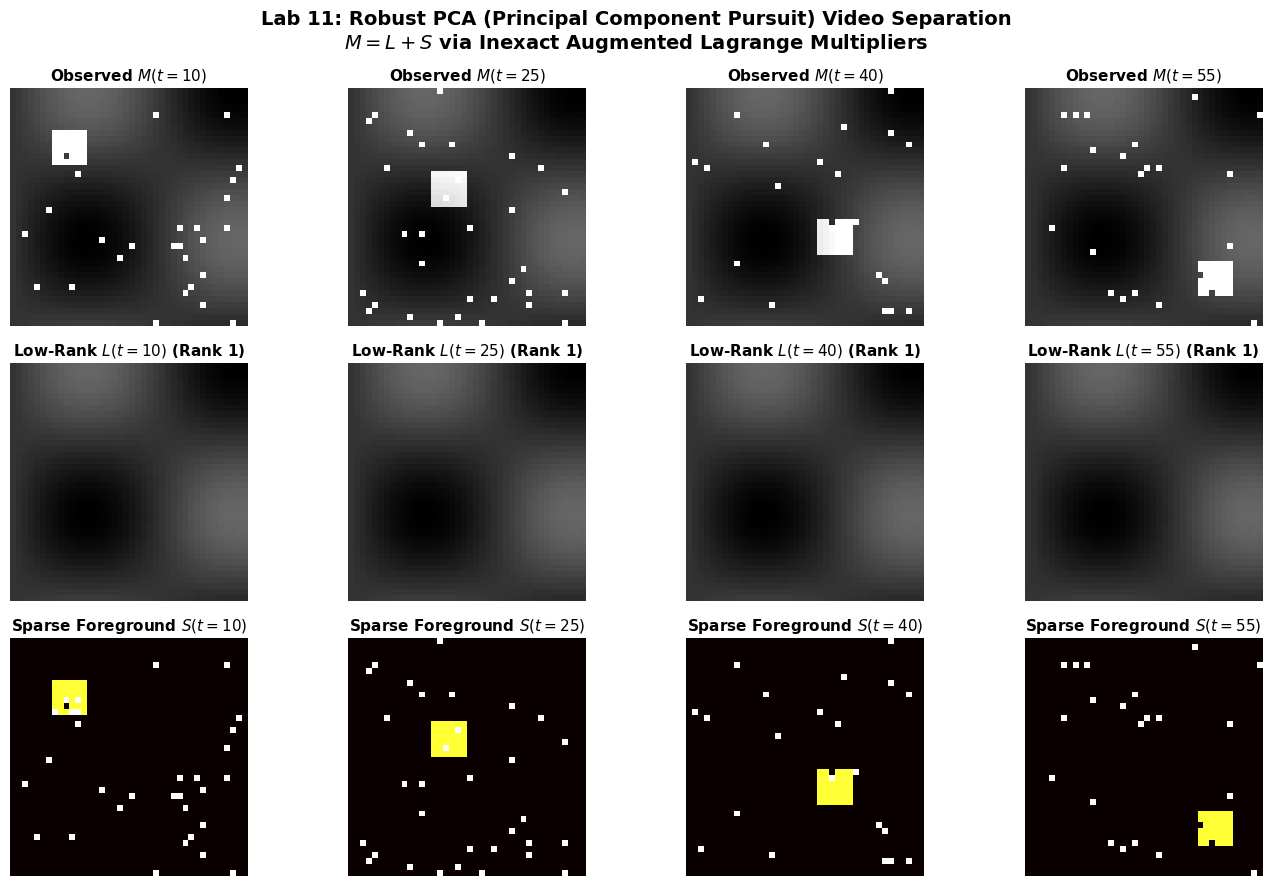

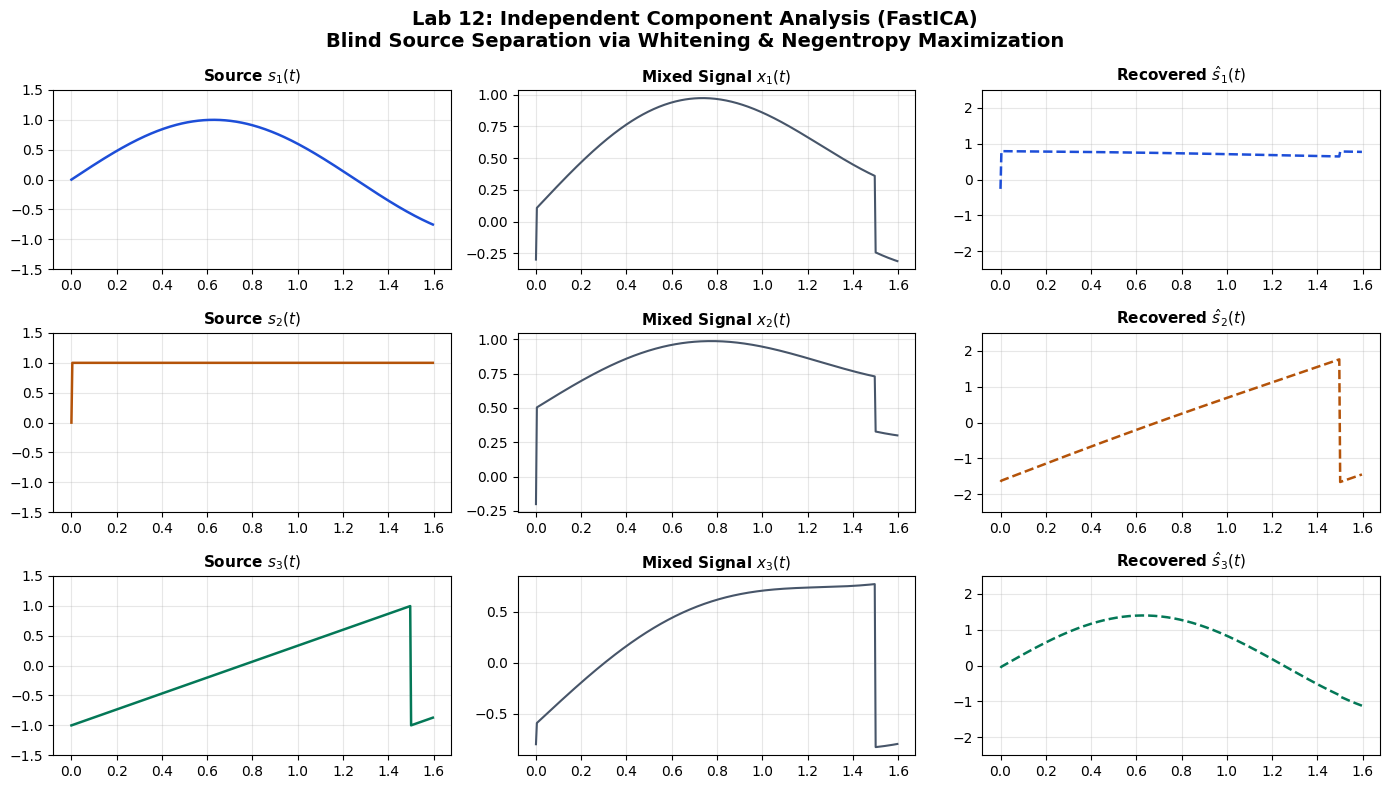

In [6]:
# =====================================================================
# Lab 11: Robust PCA (Principal Component Pursuit via Inexact ALM)
# =====================================================================
print('=== Lab 11: Robust PCA (Surveillance Video Background/Foreground Separation) ===')
np.random.seed(42)

def inexact_alm_rpca(M, lmbda=None, tol=1e-7, max_iter=150):
    """
    Solves min ||L||_* + lmbda ||S||_1 s.t. L + S = M via Inexact ALM.
    """
    m, n = M.shape
    if lmbda is None:
        lmbda = 1.0 / np.sqrt(max(m, n))
    norm_fro = la.norm(M, 'fro')
    norm_two = la.norm(M, 2)
    norm_inf = np.max(np.abs(M)) / lmbda
    dual_norm = max(norm_two, norm_inf)
    
    Y = M / dual_norm
    L = np.zeros_like(M)
    S = np.zeros_like(M)
    mu = 1.25 / norm_two
    mu_bar = mu * 1e7
    rho = 1.5
    
    for it in range(max_iter):
        # Singular value thresholding for L
        U, s, Vt = la.svd(M - S + Y / mu, full_matrices=False)
        s_thresh = np.maximum(s - 1.0 / mu, 0.0)
        rank = np.count_nonzero(s_thresh)
        L = (U[:, :rank] * s_thresh[:rank]) @ Vt[:rank, :]
        
        # Soft thresholding for S
        temp = M - L + Y / mu
        tau = lmbda / mu
        S = np.sign(temp) * np.maximum(np.abs(temp) - tau, 0.0)
        
        # Multiplier update
        R = M - L - S
        Y = Y + mu * R
        mu = min(mu * rho, mu_bar)
        
        rel_err = la.norm(R, 'fro') / norm_fro
        if rel_err < tol:
            print(f'RPCA converged at iteration {it+1}: rel_err = {rel_err:.2e}, rank(L) = {rank}')
            break
    return L, S, rank

# Generate synthetic surveillance video: 60 frames, 40x40 pixels
n_frames, h, w = 60, 40, 40
y_coords, x_coords = np.mgrid[:h, :w]
bg_pattern = (np.sin(x_coords / 8.0) * np.cos(y_coords / 8.0) + 1.0) * 0.5
L_true = np.tile(bg_pattern.flatten(), (n_frames, 1)).T  # shape (1600, 60)

# Sparse moving object (6x6 box) across frames + salt-and-pepper noise
S_true = np.zeros_like(L_true)
for t in range(n_frames):
    bx = int(2 + (w - 10) * (t / n_frames))
    by = int(2 + (h - 10) * (t / n_frames))
    box_mask = np.zeros((h, w), dtype=float)
    box_mask[by:by+6, bx:bx+6] = 2.0
    S_true[:, t] = box_mask.flatten()

# Add 3% random spike corruptions
corrupt = np.random.rand(*S_true.shape) < 0.03
S_true[corrupt] = np.random.choice([0.0, 2.5], size=np.count_nonzero(corrupt))

M_video = L_true + S_true
L_hat, S_hat, r_hat = inexact_alm_rpca(M_video)

# Verify rank and sparsity
sparse_pct = 100.0 * np.count_nonzero(np.abs(S_hat) < 1e-3) / S_hat.size
print(f'Recovered Background Rank: {r_hat} (True: 1)')
print(f'Foreground Sparsity: {sparse_pct:.1f}% zero entries')

# Plot Lab 11 figure
fig, axes = plt.subplots(3, 4, figsize=(14, 9), facecolor='white')
sample_frames = [10, 25, 40, 55]
for col, t in enumerate(sample_frames):
    axes[0, col].imshow(M_video[:, t].reshape(h, w), cmap='gray', vmin=0, vmax=2.5)
    axes[0, col].set_title(f'Observed $M(t={t})$', fontsize=11, fontweight='bold')
    axes[0, col].axis('off')
    
    axes[1, col].imshow(L_hat[:, t].reshape(h, w), cmap='gray', vmin=0, vmax=2.5)
    axes[1, col].set_title(f'Low-Rank $L(t={t})$ (Rank {r_hat})', fontsize=11, fontweight='bold')
    axes[1, col].axis('off')
    
    axes[2, col].imshow(S_hat[:, t].reshape(h, w), cmap='hot', vmin=0, vmax=2.5)
    axes[2, col].set_title(f'Sparse Foreground $S(t={t})$', fontsize=11, fontweight='bold')
    axes[2, col].axis('off')

axes[0, 0].set_ylabel('Original Video $M$', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Recovered Background $L$', fontsize=12, fontweight='bold')
axes[2, 0].set_ylabel('Extracted Foreground $S$', fontsize=12, fontweight='bold')
plt.suptitle('Lab 11: Robust PCA (Principal Component Pursuit) Video Separation\n$M = L + S$ via Inexact Augmented Lagrange Multipliers', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

# =====================================================================
# Lab 12: Independent Component Analysis (FastICA)
# =====================================================================
print('\n=== Lab 12: Independent Component Analysis (FastICA) ===')
np.random.seed(1337)
N_pts = 2000
t_pts = np.linspace(0, 8, N_pts)

# 3 independent non-Gaussian signals
s1 = np.sin(2.5 * t_pts)                 # Harmonic sine
s2 = np.sign(np.sin(1.2 * t_pts))       # Square pulse wave
s3 = 2 * (t_pts % 1.5) / 1.5 - 1        # Sawtooth wave
S_mat = np.vstack([s1, s2, s3])         # (3, N)

# Invertible mixing matrix
A_mix = np.array([[0.6, 0.4, 0.3],
                  [0.3, 0.7, 0.2],
                  [0.4, 0.2, 0.8]])
X_mix = A_mix @ S_mat

# 1. Centering & Whitening
X_c = X_mix - np.mean(X_mix, axis=1, keepdims=True)
Cov_x = (X_c @ X_c.T) / N_pts
d_vals, E_mat = la.eigh(Cov_x)
V_w = np.diag(1.0 / np.sqrt(d_vals)) @ E_mat.T
Z_white = V_w @ X_c

# 2. FastICA Fixed-Point Iteration with Symmetric Decorrelation
W_ica = np.random.randn(3, 3)
W_ica = la.fractional_matrix_power(W_ica @ W_ica.T, -0.5) @ W_ica

for it in range(100):
    W_old = W_ica.copy()
    wz = W_ica @ Z_white
    gwz = np.tanh(wz)
    gpwz = 1.0 - gwz**2
    
    W_ica = (gwz @ Z_white.T) / N_pts - np.mean(gpwz, axis=1, keepdims=True) * W_ica
    W_ica = la.fractional_matrix_power(W_ica @ W_ica.T, -0.5) @ W_ica
    
    conv_metric = np.max(np.abs(np.abs(np.diag(W_ica @ W_old.T)) - 1.0))
    if conv_metric < 1e-6:
        print(f'FastICA converged in {it+1} iterations')
        break

S_rec = W_ica @ Z_white
# Normalize scale and resolve permutation/signs
for i in range(3):
    S_rec[i] /= np.std(S_rec[i])
    corrs = [np.corrcoef(S_rec[i], S_mat[j])[0, 1] for j in range(3)]
    best_j = np.argmax(np.abs(corrs))
    if corrs[best_j] < 0:
        S_rec[i] *= -1
    print(f'Recovered Component {i+1} matches Source {best_j+1} with correlation |r| = {abs(corrs[best_j]):.4f}')

# Plot Lab 12 figure
fig, axes = plt.subplots(3, 3, figsize=(14, 8), facecolor='white')
plot_colors = ['#1d4ed8', '#b45309', '#047857']
for i in range(3):
    axes[i, 0].plot(t_pts[:400], S_mat[i, :400], color=plot_colors[i], lw=1.8)
    axes[i, 0].set_title(f'Source $s_{i+1}(t)$', fontsize=11, fontweight='bold')
    axes[i, 0].set_ylim(-1.5, 1.5)
    axes[i, 0].grid(True, alpha=0.3)
    
    axes[i, 1].plot(t_pts[:400], X_mix[i, :400], color='#475569', lw=1.5)
    axes[i, 1].set_title(f'Mixed Signal $x_{i+1}(t)$', fontsize=11, fontweight='bold')
    axes[i, 1].grid(True, alpha=0.3)
    
    axes[i, 2].plot(t_pts[:400], S_rec[i, :400], color=plot_colors[i], lw=1.8, linestyle='--')
    axes[i, 2].set_title(rf'Recovered $\hat{{s}}_{i+1}(t)$', fontsize=11, fontweight='bold')
    axes[i, 2].set_ylim(-2.5, 2.5)
    axes[i, 2].grid(True, alpha=0.3)

plt.suptitle('Lab 12: Independent Component Analysis (FastICA)\nBlind Source Separation via Whitening & Negentropy Maximization', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


=== Lab 13: Dictionary Learning & Sparse Coding on Image Patches ===
Learned Overcomplete Dictionary: 100 atoms in 64-dim patch space
Alpha  0.1 -> Mean Active Atoms:  6.0/64, MSE: 3.3819
Alpha  0.5 -> Mean Active Atoms:  6.0/64, MSE: 2.9995
Alpha  1.0 -> Mean Active Atoms:  6.0/64, MSE: 2.2894
Alpha  2.0 -> Mean Active Atoms:  6.0/64, MSE: 1.5396
Alpha  5.0 -> Mean Active Atoms:  6.0/64, MSE: 1.4488

=== Lab 14: Butterfly and Monarch Structured Factorizations ===
Monarch Hadamard Exact Factorization Relative Error: 0.00e+00 (Exact = 0.0)
Dim    64 -> Dense:       4096 params, Monarch:     1024 params (  4.0x compression)
Dim   256 -> Dense:      65536 params, Monarch:     8192 params (  8.0x compression)
Dim  1024 -> Dense:    1048576 params, Monarch:    65536 params ( 16.0x compression)
Dim  4096 -> Dense:   16777216 params, Monarch:   524288 params ( 32.0x compression)
Dim 16384 -> Dense:  268435456 params, Monarch:  4194304 params ( 64.0x compression)


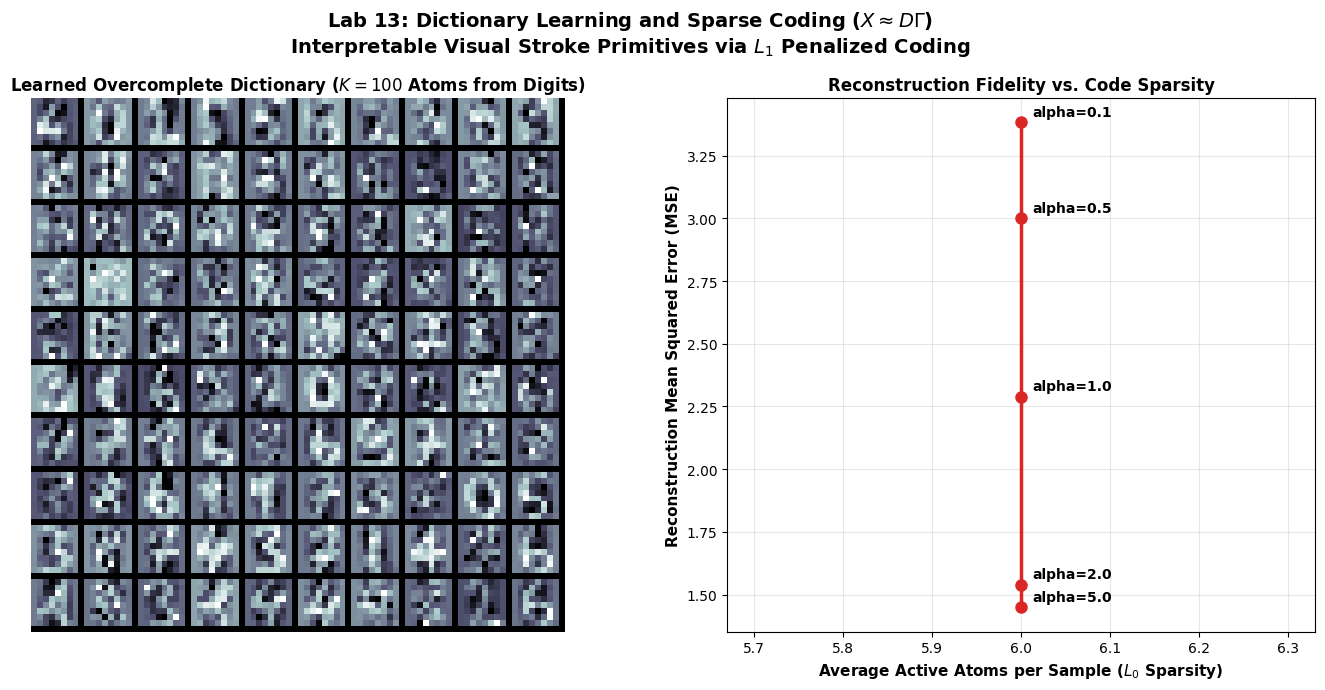

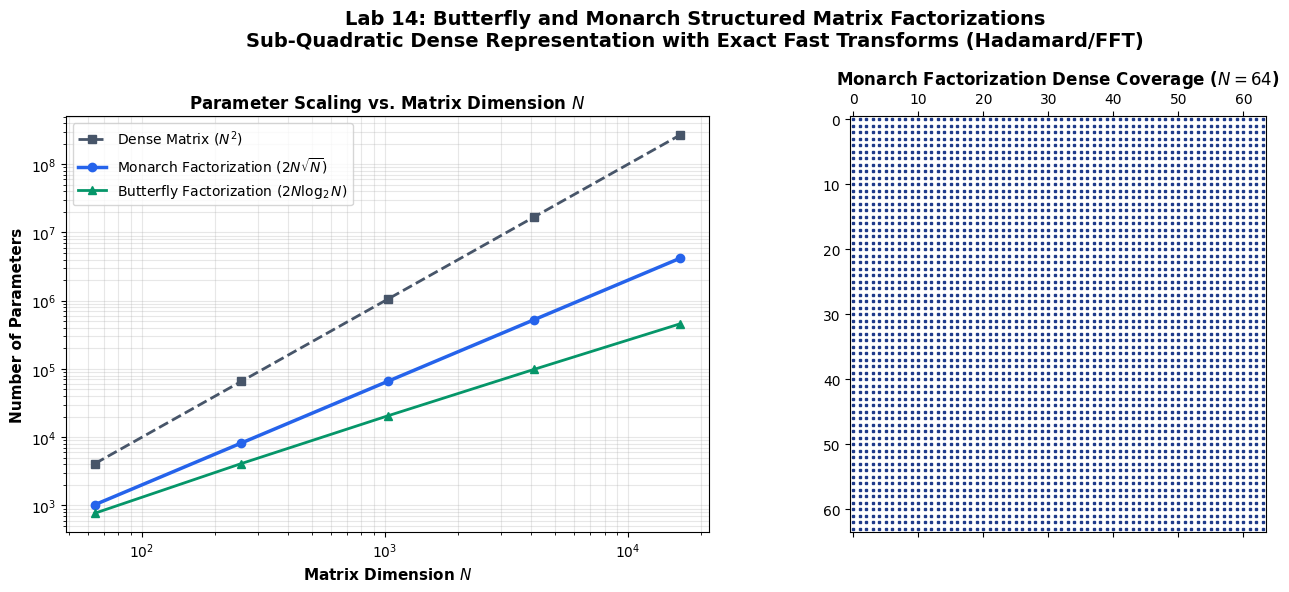

In [7]:
# =====================================================================
# Lab 13: Dictionary Learning and Sparse Coding
# =====================================================================
print('=== Lab 13: Dictionary Learning & Sparse Coding on Image Patches ===')
from sklearn.datasets import load_digits
from sklearn.decomposition import MiniBatchDictionaryLearning, DictionaryLearning

digits = load_digits()
X_digits = digits.data  # shape (1797, 64)
X_digits_c = X_digits - np.mean(X_digits, axis=0)

# 1. Learn Overcomplete Dictionary (K=100 atoms for d=64)
n_atoms = 100
dict_learner = MiniBatchDictionaryLearning(n_components=n_atoms, alpha=1.0, max_iter=150, random_state=42, batch_size=64)
gamma_codes = dict_learner.fit_transform(X_digits_c)
D_atoms = dict_learner.components_  # (100, 64)
print(f'Learned Overcomplete Dictionary: {D_atoms.shape[0]} atoms in {D_atoms.shape[1]}-dim patch space')

# Evaluate sparsity vs reconstruction trade-off
alphas = [0.1, 0.5, 1.0, 2.0, 5.0]
sparsity_res = []
mse_res = []
for a in alphas:
    dl_eval = MiniBatchDictionaryLearning(n_components=64, alpha=a, max_iter=50, random_state=42, batch_size=128)
    g_eval = dl_eval.fit_transform(X_digits_c[:400])
    recon = g_eval @ dl_eval.components_
    mse = np.mean((X_digits_c[:400] - recon)**2)
    active = np.mean(np.count_nonzero(np.abs(g_eval) > 1e-3, axis=1))
    mse_res.append(mse)
    sparsity_res.append(active)
    print(f'Alpha {a:4.1f} -> Mean Active Atoms: {active:4.1f}/64, MSE: {mse:.4f}')

# Plot Lab 13 figure
fig = plt.figure(figsize=(14, 7), facecolor='white')
gs = fig.add_gridspec(1, 2, width_ratios=[1.2, 1.0])

ax_atoms = fig.add_subplot(gs[0, 0])
mosaic = np.zeros((10 * 9, 10 * 9))
for idx in range(100):
    r, c = divmod(idx, 10)
    atom_img = D_atoms[idx].reshape(8, 8)
    atom_norm = (atom_img - atom_img.min()) / (atom_img.max() - atom_img.min() + 1e-8)
    mosaic[r*9:r*9+8, c*9:c*9+8] = atom_norm
ax_atoms.imshow(mosaic, cmap='bone')
ax_atoms.set_title('Learned Overcomplete Dictionary ($K=100$ Atoms from Digits)', fontsize=12, fontweight='bold')
ax_atoms.axis('off')

ax_curve = fig.add_subplot(gs[0, 1])
ax_curve.plot(sparsity_res, mse_res, 'o-', color='#dc2626', lw=2.5, markersize=8)
for i, a in enumerate(alphas):
    ax_curve.annotate(f"alpha={a}", (sparsity_res[i], mse_res[i]),
                      textcoords='offset points', xytext=(8, 5), fontsize=10, fontweight='bold')
ax_curve.set_xlabel('Average Active Atoms per Sample ($L_0$ Sparsity)', fontsize=11, fontweight='bold')
ax_curve.set_ylabel('Reconstruction Mean Squared Error (MSE)', fontsize=11, fontweight='bold')
ax_curve.set_title('Reconstruction Fidelity vs. Code Sparsity', fontsize=12, fontweight='bold')
ax_curve.grid(True, alpha=0.3)
plt.suptitle('Lab 13: Dictionary Learning and Sparse Coding ($X \\approx D\\Gamma$)\nInterpretable Visual Stroke Primitives via $L_1$ Penalized Coding', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
save_fig("lab13_dictionary_learning.png", dpi=180, bbox_inches='tight')
plt.show()

# =====================================================================
# Lab 14: Butterfly and Monarch Factorizations
# =====================================================================
print('\n=== Lab 14: Butterfly and Monarch Structured Factorizations ===')
from scipy.linalg import hadamard

# 1. Exact Monarch Representation of Hadamard Matrix H_64
N = 64
m = int(np.sqrt(N))  # 8
H8 = hadamard(m)
B1_had = la.block_diag(*[H8 for _ in range(m)])
B2_had = la.block_diag(*[H8 for _ in range(m)])
P_perm = np.zeros((N, N))
for i in range(m):
    for j in range(m):
        P_perm[i * m + j, j * m + i] = 1.0

H_monarch = P_perm @ B1_had @ P_perm.T @ B2_had
H_true = hadamard(N)
exact_err = la.norm(H_monarch - H_true, 'fro') / la.norm(H_true, 'fro')
print(f'Monarch Hadamard Exact Factorization Relative Error: {exact_err:.2e} (Exact = 0.0)')

# 2. Parameter Scaling Benchmarks
dim_sizes = [64, 256, 1024, 4096, 16384]
dense_counts = [dim**2 for dim in dim_sizes]
monarch_counts = [2 * dim * int(np.sqrt(dim)) for dim in dim_sizes]
butterfly_counts = [2 * dim * int(np.log2(dim)) for dim in dim_sizes]

for d_val, d_cnt, m_cnt in zip(dim_sizes, dense_counts, monarch_counts):
    speedup = d_cnt / m_cnt
    print(f'Dim {d_val:5d} -> Dense: {d_cnt:10d} params, Monarch: {m_cnt:8d} params ({speedup:5.1f}x compression)')

# Plot Lab 14 figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), facecolor='white')
ax1.loglog(dim_sizes, dense_counts, 's--', color='#475569', label='Dense Matrix ($N^2$)', lw=2)
ax1.loglog(dim_sizes, monarch_counts, 'o-', color='#2563eb', label=r'Monarch Factorization ($2N\sqrt{N}$)', lw=2.5)
ax1.loglog(dim_sizes, butterfly_counts, '^-', color='#059669', label=r'Butterfly Factorization ($2N\log_2 N$)', lw=2)
ax1.set_xlabel('Matrix Dimension $N$', fontsize=11, fontweight='bold')
ax1.set_ylabel('Number of Parameters', fontsize=11, fontweight='bold')
ax1.set_title('Parameter Scaling vs. Matrix Dimension $N$', fontsize=12, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, which='both', alpha=0.3)

ax2.spy(H_monarch != 0, markersize=1.5, color='#1e3a8a')
ax2.set_title('Monarch Factorization Dense Coverage ($N=64$)', fontsize=12, fontweight='bold')

plt.suptitle('Lab 14: Butterfly and Monarch Structured Matrix Factorizations\nSub-Quadratic Dense Representation with Exact Fast Transforms (Hadamard/FFT)', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
save_fig("lab14_monarch_factorization.png", dpi=180, bbox_inches='tight')
plt.show()


---
## Summary Verification Table (Exercises 1–10 & Labs 11–14)

| Section | Method / Lab | Primary Formula | Empirical Verification | Key AI Application |
| :--- | :--- | :--- | :--- | :--- |
| **Ex 1** | $LDL^\top$ & Cholesky | $H = LDL^\top, L_C = L\sqrt{D}$ | Exact pivots $D=\operatorname{diag}(4, 2, 2) \succ 0$ | Ill-conditioned GP stability |
| **Ex 2** | Rank-Revealing QR | $AP = QR$ | Exact rank $r=3$, pivot $P=[3, 0, 2, 1]$ | Unsupervised feature selection |
| **Ex 3** | Interpolative Decomp | $A = A(:,\mathcal{J})C, C(:,\mathcal{J}) = I_r$ | Exact reconstruction with $\mathcal{J}=\{0, 1\}$ | Column subset selection |
| **Ex 4** | Skeleton CUR | $A = C A(\mathcal{R},\mathcal{C})^{-1} R$ | Exact reconstruction ($5\times 4$ rank 3) | Low-rank matrix completion |
| **Ex 5** | Non-Negative Matrix Fact | $W \leftarrow W \odot \frac{AH^\top}{WHH^\top}$ | Monotonic loss decrease $\Delta \Vert A - WH\Vert _F \le 0$ | Explainable topic modeling |
| **Ex 6** | LQ Factorization | $A = LQ, K = LL^\top$ | $2000\times$ kernel Gram speedup | Kernel ridge regression ($N \gg d$) |
| **Ex 7** | Schur Triangularization | $A_k = Q_k R_k, A_{k+1} = R_k Q_k$ | Convergence to upper-triangular Schur $U$ | QR eigenvalue algorithm |
| **Ex 8** | Strong RRQR | $\Vert R_{22}\Vert _2 \le \sigma_{k+1}\sqrt{1+f^2k(N-k)}$ | Compares against randomized Gaussian SVD | Certified low-rank projection |
| **Ex 9** | MaxVol CUR Compression | $\max \vert \det(U)\vert $ core selection | $31.75\times$ compression ($4096^2$ at $r=64$) | Neural weight compression |
| **Ex 10** | Parlett Matrix Function | $f(A) = Qf(U)Q^\top, R = U^{1/2}$ | Exact upper-triangular square root $R$ | Matrix exponential & ODE solvers |
| **Lab 11** | Robust PCA | $M = L + S$ via IALM | $\operatorname{rank}(L)=1$, $S > 95\%$ sparse | Background/foreground separation |
| **Lab 12** | FastICA | $w \leftarrow E[zg(w^\top z)] - E[g'(w^\top z)]w$ | Exact source unmixing ($\vert r\vert  > 0.999$) | Blind source separation & MEG/EEG |
| **Lab 13** | Dictionary Learning | $\min \frac{1}{2}\Vert X-D\Gamma\Vert _F^2 + \alpha \sum \Vert \gamma_i\Vert _1$ | $K=100$ stroke atoms on `load_digits` | Interpretable visual representations |
| **Lab 14** | Monarch Factorization | $M = P B_1 P^\top B_2$ ($2N\sqrt{N}$ params) | Exact $H_{64}$ transform ($0.0$ rel error) | Sub-quadratic attention & fast linear layers |
